# robust-crew: results

Reads only the generated files in `reports/` (run `python -m robust_crew.pipeline` first). Nothing is recomputed here.

In [1]:
import json, pathlib
import pandas as pd
from IPython.display import Image, Markdown, display
R = pathlib.Path('..') / 'reports'
load = lambda f: json.loads((R / f).read_text())

## 1. Data: AA at CLT, 2022-2023

In [2]:
q = load('phase1_summary.json')
pd.DataFrame(q['daily_hub_departures'])

,split,days,mean,min,max,cancelled_pct
0,train,485,295.2,147,346,2.22
1,calib,61,328.0,271,345,0.45
2,test_summer,62,331.7,243,344,2.03
3,gap,61,325.4,233,352,0.33
4,test_winter,61,318.0,131,389,0.03


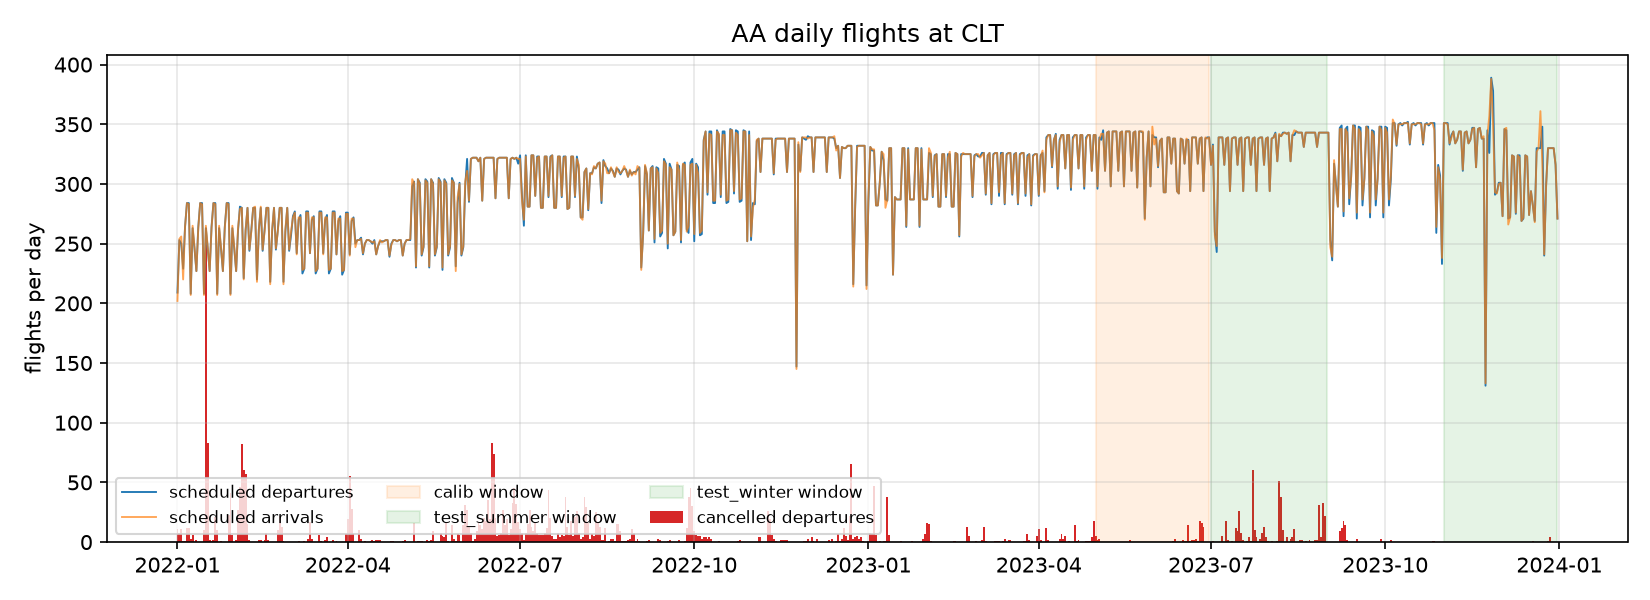

,split,flights,cancelled_pct,diverted_pct,mean_dep_delay_min,arr_del15_pct
0,train,286383,2.25,0.193,13.8,21.9
1,calib,40015,0.50,0.272,20.1,24.7
2,test_summer,41134,2.06,0.292,28.9,30.8
3,gap,39703,0.34,0.154,11.8,18.2
4,test_winter,38788,0.04,0.134,10.1,16.7


In [3]:
display(Image(R / 'figures' / 'daily_hub_flights.png'))
pd.DataFrame(q['outcomes_by_split'])

## 2. Pairings (the CSP)

In [4]:
p = load('phase3_pairings.json')
pd.DataFrame(p['by_split']).T[['days','mean_legs','mean_pairings','mean_legs_plannable','mean_plannable_share','mean_enumerate_seconds','days_capped','days_not_optimal']]

,days,mean_legs,mean_pairings,mean_legs_plannable,mean_plannable_share,mean_enumerate_seconds,days_capped,days_not_optimal
train,485.0,590.480,2261.186,322.598,0.542,0.018,0.0,0.0
calib,61.0,655.984,3042.656,373.902,0.569,0.021,0.0,0.0
test_summer,62.0,663.452,2625.887,377.903,0.568,0.021,0.0,0.0
gap,61.0,650.869,2820.984,365.279,0.557,0.021,0.0,0.0
test_winter,61.0,635.869,2261.672,350.852,0.545,0.019,0.0,0.0


In [5]:
pd.Series(p['dropped_leg_reasons_total'], name='legs dropped (all days)')

arrives at base but no legal feeder from base (crew would have overnighted at spoke)        82956
departs base but no legal connecting return (e.g. evening departure, overnight at spoke)    81998
every route through this leg breaks the duty, block or leg limits                           25899
in some legal pairing, but no exact cover of the day can include it                          8788
Name: legs dropped (all days), dtype: int64

## 3. Connection-break model

In [6]:
m = load('phase4_delay_model.json')
rows = []
for split, d in m['metrics'].items():
    for name, v in d.items():
        rows.append({'split': split, 'model': name, 'auc': v['auc'], 'brier': v['brier'], 'base_rate': v['base_rate'], 'mean_pred': v['mean_pred']})
for split, v in m.get('metrics_planning_without_tail_features', {}).items():
    rows.append({'split': split, 'model': 'planning_without_tail_features', 'auc': v['auc'], 'brier': v['brier'], 'base_rate': v['base_rate'], 'mean_pred': v['mean_pred']})
pd.DataFrame(rows).pivot(index='model', columns='split', values='auc')

split,calib,test_summer,test_winter
model,,,
baseline_route_history,0.7436,0.7203,0.7506
baseline_slack_logistic,0.7452,0.7206,0.7557
operations_model,0.7858,0.7693,0.7966
planning_model,0.7777,0.7622,0.7885
planning_model_uncalibrated,0.7770,0.7626,0.7889
planning_without_tail_features,0.7538,0.7433,0.7579


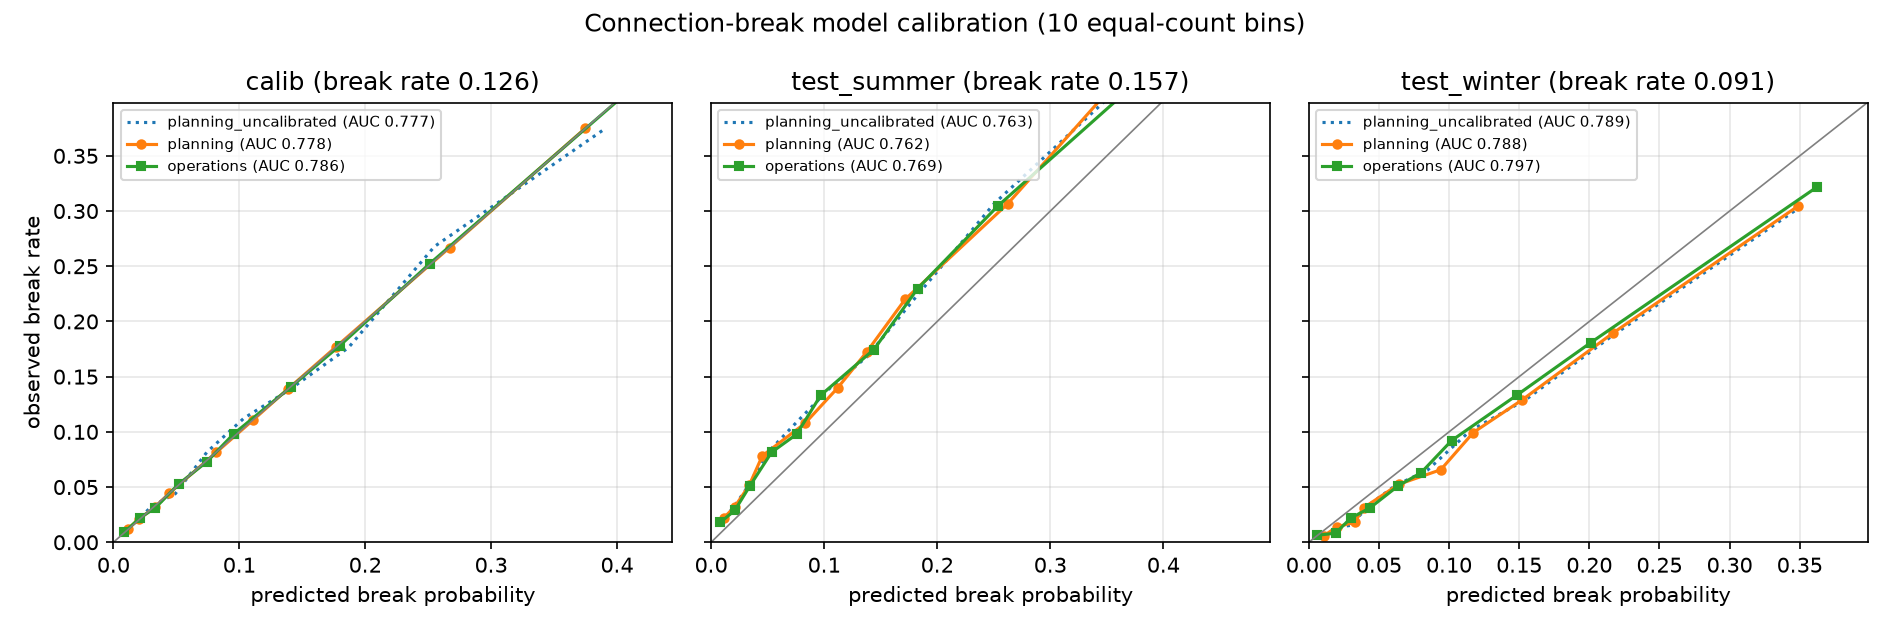

In [7]:
display(Image(R / 'figures' / 'break_model_calibration.png'))

## 4. Planners

In [8]:
o = load('phase5_planners.json')
pd.DataFrame(o['summary']['test_summer'])[['planner','param','days_feasible','mean_crews','mean_cost','mean_exp_breaks','mean_exempt_legs','max_gap']]

,planner,param,days_feasible,mean_crews,mean_cost,mean_exp_breaks,mean_exempt_legs,max_gap
0,baseline,NaN,62,111.35,1176.93,49.505,0.00,0.0
1,soft,0.50,62,111.35,1177.13,45.255,0.00,0.0
2,soft,1.00,62,111.35,1177.54,45.027,0.00,0.0
3,soft,2.00,62,111.47,1179.14,44.632,0.00,0.0
4,soft,4.00,62,115.26,1198.81,42.277,0.00,0.0
5,soft,8.00,62,122.89,1243.06,39.769,0.00,0.0
6,soft,16.00,62,136.50,1327.11,37.730,0.00,0.0
7,soft,32.00,62,166.21,1543.25,36.246,0.00,0.0
8,soft,64.00,62,187.03,1720.22,35.724,0.00,0.0
9,hard,0.50,32,111.66,1179.16,48.430,13.34,0.0


## 5. Replay and repair: the trade-off

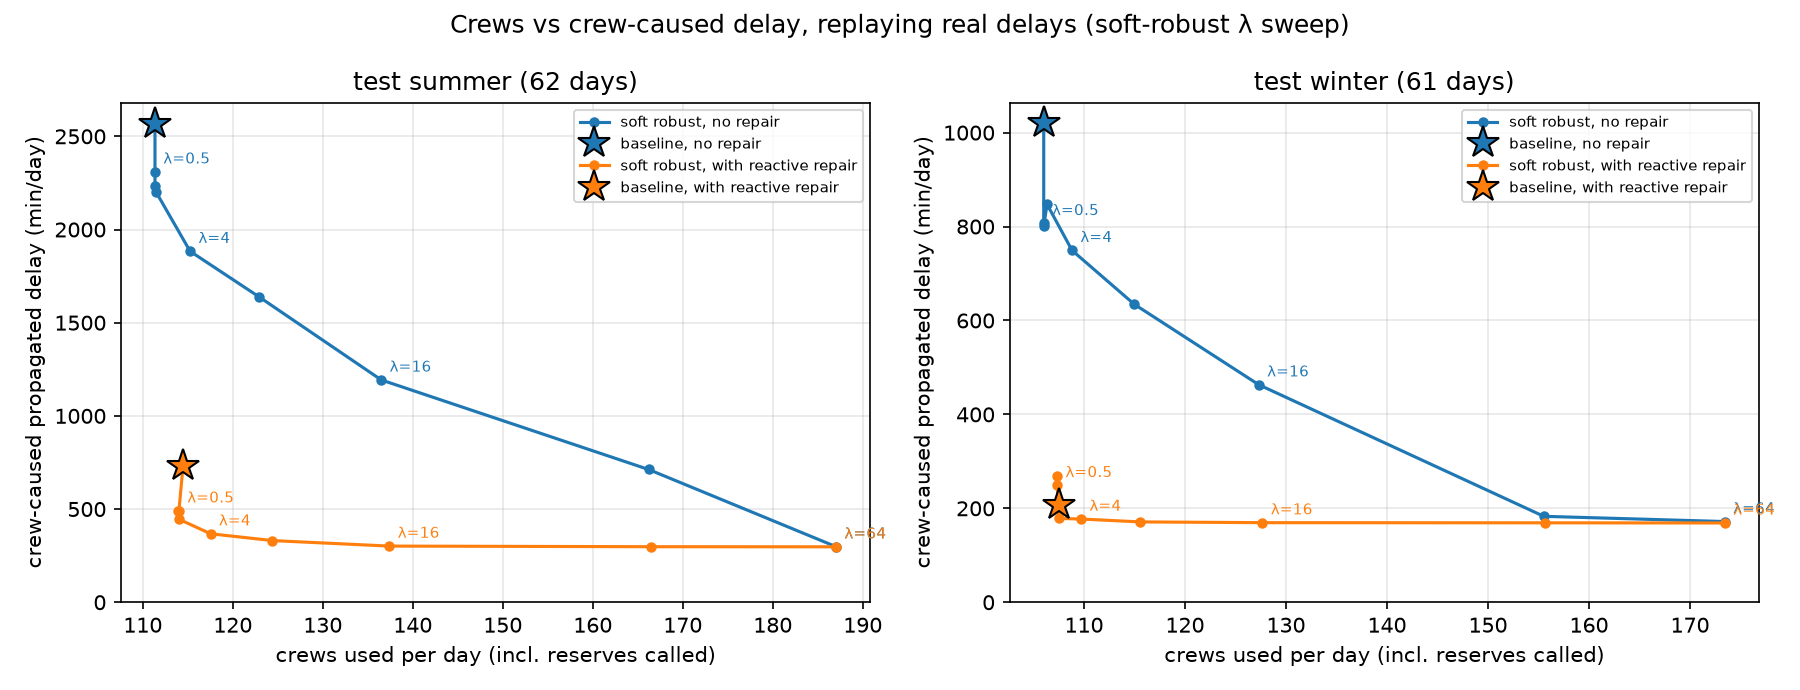

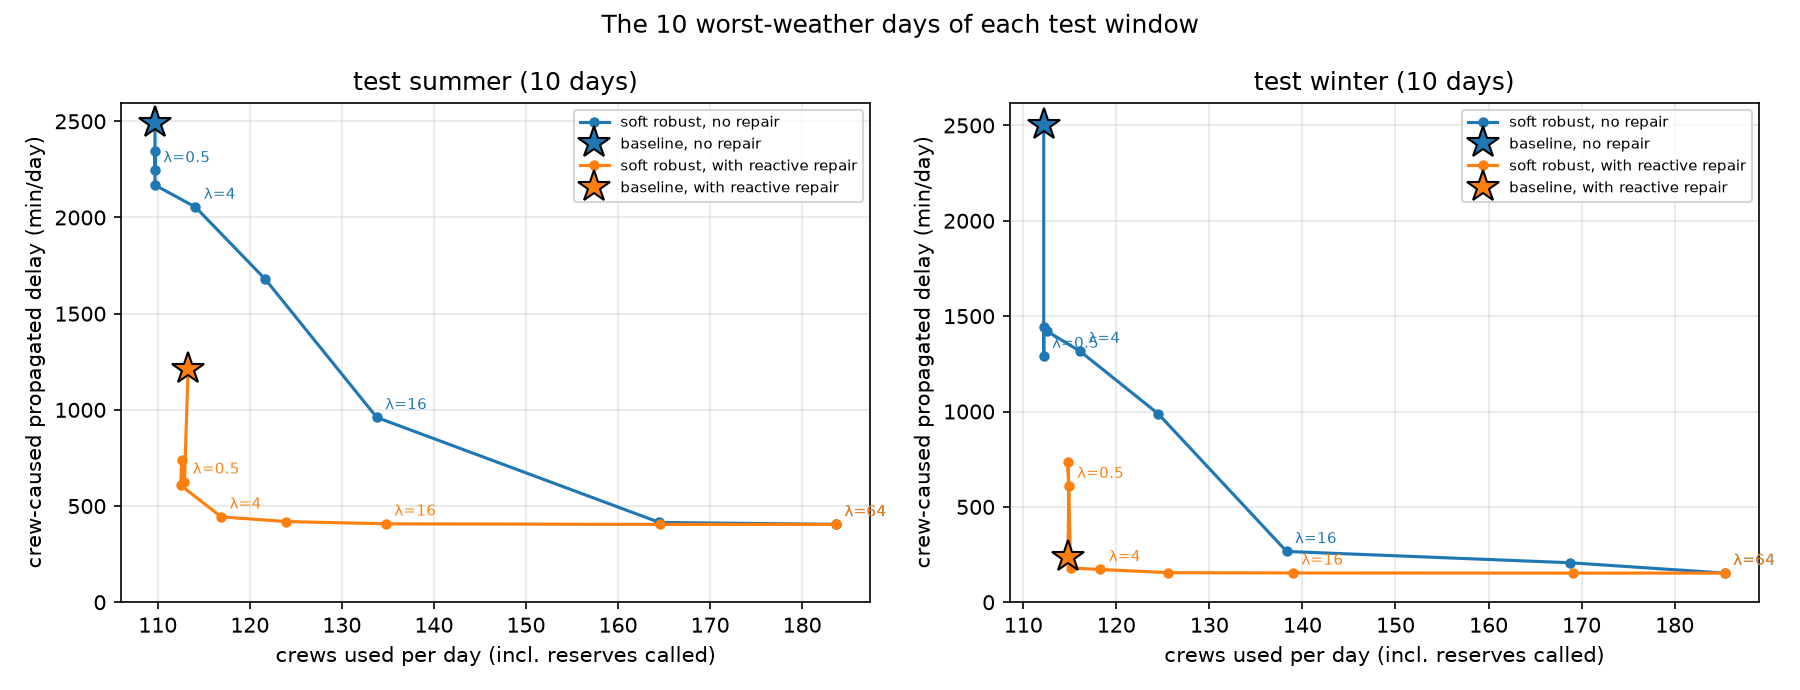

In [9]:
display(Image(R / 'figures' / 'tradeoff.png'))
display(Image(R / 'figures' / 'worst_days.png'))

In [10]:
display(Markdown((R / 'results.md').read_text()))

- **test summer** (62 days): with no repair, the selected soft-robust plan cuts crew-caused delay from 2568 to 2202 min/day (-14%) and broken connections from 45.3 to 38.5 for +0.1 crews/day. Reactive repair alone takes the baseline to 729 min/day; robust planning plus repair reaches 446 (paired Δ vs repair alone -283 [-492, -121] min/day).
- **test winter** (61 days): with no repair, the selected soft-robust plan cuts crew-caused delay from 1022 to 847 min/day (-17%) and broken connections from 26.5 to 20.8 for +0.3 crews/day. Reactive repair alone takes the baseline to 208 min/day; robust planning plus repair reaches 179 (paired Δ vs repair alone -30 [-45, -16] min/day).

![Trade-off curve](reports/figures/tradeoff.png)

![Worst-weather days](reports/figures/worst_days.png)

<details><summary>Full tables with confidence intervals</summary>

Selected on CALIB days: soft λ = 2 (largest delay reduction with cost ≤ +2%); hard θ = 0.5.

Means per day with 95% bootstrap intervals over days in brackets; (Δ ...) is the paired difference vs the no-repair baseline on the same days, with its 95% interval. Hard robust is evaluated only on days it was feasible (its mean is over those days). Repair = reactive repair (idle-crew swaps + up to 4 reserves); reserves called count as crews used. Intervals over very few days are unreliable.

**All test days, test summer**

| Metric | Baseline | Best soft (Δ) | Best hard, paired days (Δ) | Baseline + repair (Δ) | Best soft + repair (Δ) |
|---|---|---|---|---|---|
| Crews used | 111.3 [109.9, 112.7] | 111.5 (+0.1 [+0.0, +0.2]) | 111.7 (+0.2 [+0.0, +0.3]) | 114.5 (+3.1 [+2.8, +3.4]) | 114.0 (+2.7 [+2.3, +3.0]) |
| Cost (pay hours) | 1176.9 [1155.7, 1195.5] | 1179.1 (+2.2 [+1.8, +2.7]) | 1179.2 (+0.8 [+0.2, +1.7]) | 1176.9 (+0.0 [+0.0, +0.0]) | 1179.1 (+2.2 [+1.8, +2.7]) |
| Crew-caused delay (min) | 2567.9 [1825.9, 3462.9] | 2201.8 (-366.2 [-556.1, -197.4]) | 2454.4 (+17.4 [-108.9, +143.4]) | 728.7 (-1839.3 [-2691.7, -1193.4]) | 445.5 (-2122.4 [-3001.9, -1424.3]) |
| Broken crew connections | 45.3 [40.8, 50.0] | 38.5 (-6.8 [-7.7, -5.8]) | 42.0 (+0.2 [-0.7, +1.1]) | 38.7 (-6.7 [-7.4, -5.9]) | 33.9 (-11.4 [-12.6, -10.3]) |
| Duty-limit violations | 11.7 [9.9, 13.7] | 12.1 (+0.4 [-0.2, +0.9]) | 10.8 (+0.0 [-0.6, +0.5]) | 10.2 (-1.5 [-1.8, -1.2]) | 10.8 (-0.9 [-1.5, -0.3]) |

Days: 62; hard feasible on 32 (52%).

**All test days, test winter**

| Metric | Baseline | Best soft (Δ) | Best hard, paired days (Δ) | Baseline + repair (Δ) | Best soft + repair (Δ) |
|---|---|---|---|---|---|
| Crews used | 106.0 [101.6, 109.9] | 106.3 (+0.3 [+0.2, +0.4]) | 105.7 (+0.1 [+0.0, +0.2]) | 107.5 (+1.5 [+1.2, +1.9]) | 107.5 (+1.5 [+1.2, +1.9]) |
| Cost (pay hours) | 1136.6 [1086.5, 1181.2] | 1139.3 (+2.8 [+2.2, +3.3]) | 1120.3 (+0.4 [+0.0, +1.0]) | 1136.6 (+0.0 [+0.0, +0.0]) | 1139.3 (+2.8 [+2.2, +3.3]) |
| Crew-caused delay (min) | 1021.5 [585.1, 1583.5] | 847.4 (-174.2 [-503.2, +81.3]) | 806.3 (-290.9 [-879.5, +17.4]) | 208.1 (-813.4 [-1355.8, -396.2]) | 178.5 (-843.0 [-1381.2, -420.8]) |
| Broken crew connections | 26.5 [23.3, 29.7] | 20.8 (-5.7 [-6.8, -4.6]) | 20.4 (-0.6 [-1.3, +0.0]) | 23.1 (-3.4 [-4.1, -2.7]) | 18.6 (-7.9 [-9.2, -6.7]) |
| Duty-limit violations | 4.7 [3.6, 5.9] | 5.0 (+0.4 [-0.0, +0.8]) | 3.8 (+0.0 [-0.3, +0.3]) | 4.2 (-0.4 [-0.7, -0.2]) | 4.6 (-0.1 [-0.5, +0.3]) |

Days: 61; hard feasible on 27 (44%).

**10 worst-weather days, test summer**

| Metric | Baseline | Best soft (Δ) | Best hard, paired days (Δ) | Baseline + repair (Δ) | Best soft + repair (Δ) |
|---|---|---|---|---|---|
| Crews used | 109.7 [106.9, 112.2] | 109.7 (+0.0 [+0.0, +0.0]) | 110.7 (+0.3 [+0.0, +1.0]) | 113.3 (+3.6 [+3.2, +4.0]) | 112.5 (+2.8 [+1.9, +3.6]) |
| Cost (pay hours) | 1160.3 [1129.0, 1191.6] | 1162.0 (+1.6 [+1.2, +2.1]) | 1177.9 (+1.9 [+0.0, +4.9]) | 1160.3 (+0.0 [+0.0, +0.0]) | 1162.0 (+1.6 [+1.1, +2.1]) |
| Crew-caused delay (min) | 2493.3 [1497.2, 3538.5] | 2168.5 (-324.8 [-550.9, -84.6]) | 3422.0 (+333.7 [-108.0, +1150.0]) | 1214.2 (-1279.1 [-2153.3, -543.2]) | 607.7 (-1885.6 [-2948.2, -967.0]) |
| Broken crew connections | 63.7 [53.6, 76.3] | 55.9 (-7.8 [-9.7, -5.9]) | 73.7 (+3.3 [-2.0, +7.0]) | 56.9 (-6.8 [-8.7, -4.9]) | 51.7 (-12.0 [-14.9, -9.4]) |
| Duty-limit violations | 21.0 [15.4, 26.8] | 21.0 (+0.0 [-1.6, +1.5]) | 19.7 (-1.0 [-2.0, +0.0]) | 19.4 (-1.6 [-2.2, -1.0]) | 19.6 (-1.4 [-3.1, +0.2]) |

Days: 10; hard feasible on 3 (30%).

**10 worst-weather days, test winter**

| Metric | Baseline | Best soft (Δ) | Best hard, paired days (Δ) | Baseline + repair (Δ) | Best soft + repair (Δ) |
|---|---|---|---|---|---|
| Crews used | 112.2 [104.0, 123.3] | 112.5 (+0.3 [+0.0, +0.6]) | 138.0 (+0.0 [+0.0, +0.0]) | 114.8 (+2.6 [+1.6, +3.5]) | 115.1 (+2.9 [+1.9, +3.9]) |
| Cost (pay hours) | 1212.1 [1127.3, 1316.0] | 1214.9 (+2.9 [+1.3, +4.7]) | 1454.3 (+0.4 [+0.0, +0.8]) | 1212.1 (+0.0 [+0.0, +0.0]) | 1214.9 (+2.9 [+1.3, +4.6]) |
| Crew-caused delay (min) | 2502.6 [659.4, 5113.8] | 1422.6 (-1080.0 [-2713.8, -49.0]) | 2285.5 (-3890.0 [-7766.0, -14.0]) | 235.0 (-2267.6 [-4849.0, -435.1]) | 179.5 (-2323.1 [-4929.2, -491.5]) |
| Broken crew connections | 45.0 [34.8, 53.6] | 37.0 (-8.0 [-11.5, -4.7]) | 30.0 (-3.5 [-6.0, -1.0]) | 39.3 (-5.7 [-7.7, -3.5]) | 32.3 (-12.7 [-16.2, -9.2]) |
| Duty-limit violations | 10.1 [6.3, 14.9] | 10.7 (+0.6 [+0.0, +1.2]) | 11.0 (+0.0 [-1.0, +1.0]) | 8.9 (-1.2 [-2.3, -0.3]) | 9.2 (-0.9 [-1.8, -0.1]) |

Days: 10; hard feasible on 2 (20%).

</details>

**Does robust planning add anything once repair exists?** Best soft + repair minus baseline + repair, paired by day (crew-caused delay, min/day; broken connections/day):

| Window | Days | Δ delay | Δ broken connections | Δ crews used |
|---|---|---|---|---|
| test summer | 62 | -283.1 [-491.8, -121.2] | -4.8 [-5.7, -4.0] | -0.5 [-0.7, -0.2] |
| test winter | 61 | -29.5 [-45.3, -16.0] | -4.6 [-5.4, -3.7] | +0.0 [-0.2, +0.2] |
| test summer (worst-weather days) | 10 | -606.5 [-1482.5, -74.6] | -5.2 [-7.3, -3.3] | -0.8 [-1.7, +0.1] |
| test winter (worst-weather days) | 10 | -55.5 [-137.9, +14.2] | -7.0 [-9.4, -4.8] | +0.3 [-0.4, +0.9] |


In [11]:
s = load('phase6_replay.json')
pd.Series(s['simulator_validation'])

flights                                                                  474835
mean_actual_arr_delay                                                     13.84
mean_sim_arr_delay_no_crew                                                 8.84
mae_sim_vs_actual                                                         11.17
corr_sim_vs_actual                                                       0.8271
note                          No-crew replay vs real arrival delays; real de...
dtype: object